In [ ]:
!pip install roboflow

from roboflow import Roboflow
from google.colab import userdata
rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("nikimauzer-rscbx").project("cs2-shsmv")
version = project.version(1)
dataset = version.download("yolov8")


In [3]:
from shutil import make_archive

make_archive("/content/cs2", "zip", root_dir=dataset.location)

'/content/cs2.zip'

# 1. Загрузка датасета CS2 и проверка разметки

In [4]:
from hashlib import sha256
from pathlib import PurePosixPath
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import yaml

image_rows = []
box_rows = []
errors = []
tolerance = 1e-5

with ZipFile("/content/cs2.zip") as archive:
    files = set(archive.namelist())
    yaml_path = next(
        (name for name in sorted(files) if PurePosixPath(name).name == "data.yaml"),
        None,
    )
    if yaml_path is None:
        raise ValueError("В архиве нет data.yaml. Проверь формат экспорта YOLOv8.")

    names = yaml.safe_load(archive.read(yaml_path))["names"]
    class_names = (
        dict(enumerate(names))
        if isinstance(names, list)
        else {int(key): value for key, value in names.items()}
    )

    for filename in sorted(files):
        path = PurePosixPath(filename)
        if path.parent.name != "images":
            continue
        if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
            continue

        split = path.parent.parent.name
        label_path = str(path.parent.parent / "labels" / f"{path.stem}.txt")
        has_labels = label_path in files
        lines = (
            archive.read(label_path).decode("utf-8-sig").splitlines()
            if has_labels else []
        )
        lines = [line for line in lines if line.strip()]
        box_count = 0

        for line in lines:
            try:
                raw_class, *coords = line.split()
                class_id = int(raw_class)
                x, y, width, height = map(float, coords)

                if class_id not in class_names:
                    raise ValueError("Неизвестный класс")
                if not (0 <= x <= 1 and 0 <= y <= 1
                        and 0 < width <= 1 and 0 < height <= 1):
                    raise ValueError("Недопустимые координаты или размер")
            except ValueError as error:
                errors.append({"file": label_path, "line": line, "error": str(error)})
                continue

            outside = (
                x - width / 2 < -tolerance
                or x + width / 2 > 1 + tolerance
                or y - height / 2 < -tolerance
                or y + height / 2 > 1 + tolerance
            )
            box_rows.append({
                "split": split,
                "class": class_names[class_id],
                "area_pct": width * height * 100,
                "outside": outside,
            })
            box_count += 1

        image_rows.append({
            "split": split,
            "image": filename,
            "boxes": box_count,
            "missing_txt": not has_labels,
            "empty_txt": has_labels and not lines,
            "hash": sha256(archive.read(filename)).hexdigest(),
        })

if not image_rows or not box_rows:
    raise ValueError("Не найдены изображения или рамки. Проверь содержимое архива.")

frames = pd.DataFrame(image_rows)
objects = pd.DataFrame(box_rows)

print("Классы:", class_names)
print("Кадров:", len(frames))
print("Рамок:", len(objects))

Классы: {0: 'Counter terrorist', 1: 'T'}
Кадров: 4857
Рамок: 6009


# 2. Размер выборок, баланс классов и дубликаты

In [5]:
summary = frames.groupby("split").agg(
    кадров=("image", "size"),
    рамок=("boxes", "sum"),
    кадров_без_рамок=("boxes", lambda counts: counts.eq(0).sum()),
    кадров_без_txt=("missing_txt", "sum"),
    пустых_txt=("empty_txt", "sum"),
).reindex(["train", "valid", "test"]).dropna().astype(int)

summary["доля_кадров_%"] = (summary["кадров"] / len(frames) * 100).round(1)
display(summary)

class_counts = (
    pd.crosstab(objects["split"], objects["class"])
    .reindex(index=summary.index, columns=list(class_names.values()), fill_value=0)
)
print("Число объектов каждого класса:")
display(class_counts)

print("Площадь рамок в процентах от площади кадра:")
display(
    objects.groupby("class")["area_pct"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95])
    .round(2)
)

split_counts = frames.groupby("hash")["split"].nunique()
shared_hashes = split_counts[split_counts.gt(1)].index

print("Строк разметки с ошибками:", len(errors))
print("Рамок, выходящих за границы кадра:", objects["outside"].sum())
print("Повторных файлов сверх первого вхождения:", frames["hash"].duplicated().sum())
print("Одинаковых файлов, встречающихся в разных выборках:", len(shared_hashes))

if errors:
    display(pd.DataFrame(errors).head(10))

if len(shared_hashes):
    display(frames.loc[frames["hash"].isin(shared_hashes), ["split", "image"]].head(10))

,кадров,рамок,кадров_без_рамок,кадров_без_txt,пустых_txt,доля_кадров_%
split,,,,,,
train,4411,5462,0,0,0,90.8
valid,360,430,3,0,3,7.4
test,86,117,0,0,0,1.8


Число объектов каждого класса:


class,Counter terrorist,T
split,,
train,2824,2638
valid,222,208
test,58,59


Площадь рамок в процентах от площади кадра:


,count,mean,std,min,25%,50%,75%,95%,max
class,,,,,,,,,
Counter terrorist,3104.0,3.14,8.10,0.03,0.29,0.70,2.19,13.15,86.09
T,2905.0,3.00,6.77,0.02,0.19,0.63,2.13,15.91,60.56


Строк разметки с ошибками: 0
Рамок, выходящих за границы кадра: 0
Повторных файлов сверх первого вхождения: 0
Одинаковых файлов, встречающихся в разных выборках: 0


# 3. Отчётные графики

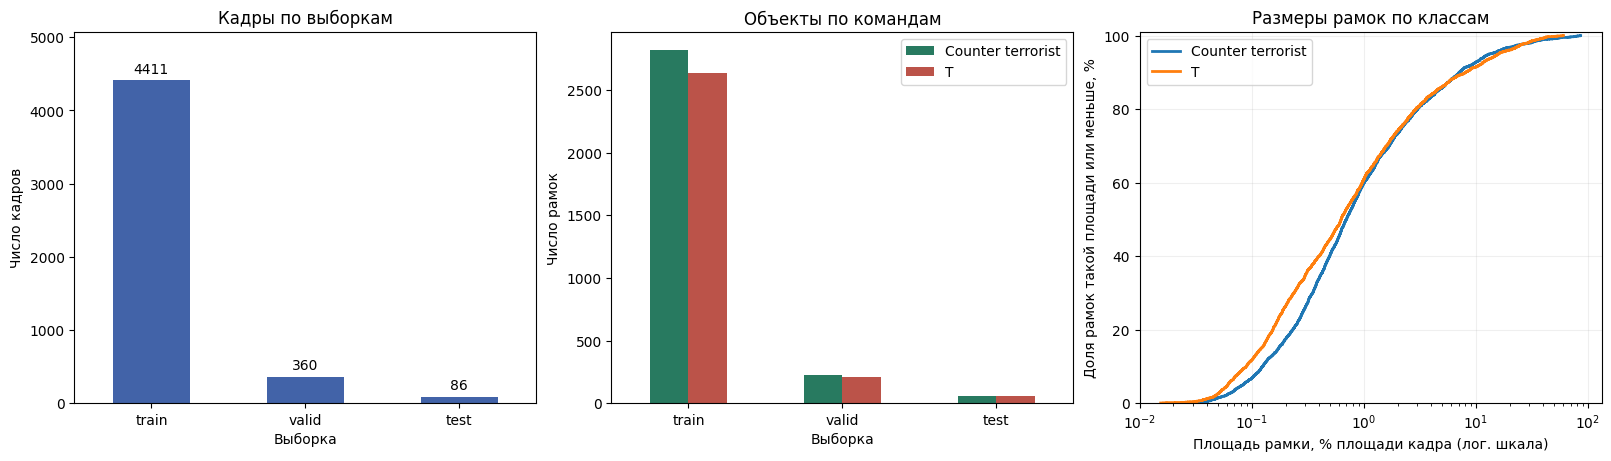

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout="constrained")

summary["кадров"].plot.bar(ax=axes[0], color="#4263a8", rot=0)
axes[0].set(title="Кадры по выборкам", xlabel="Выборка", ylabel="Число кадров")
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].margins(y=0.15)

class_counts.plot.bar(ax=axes[1], rot=0, color=["#287a60", "#bb5349"])
axes[1].set(title="Объекты по командам", xlabel="Выборка", ylabel="Число рамок")
axes[1].legend(title=None)

for label, group in objects.groupby("class"):
    area = group["area_pct"].value_counts().sort_index()
    cumulative = area.cumsum() / area.sum() * 100
    axes[2].step(area.index, cumulative, where="post", label=label, linewidth=2)

axes[2].set(
    title="Размеры рамок по классам",
    xlabel="Площадь рамки, % площади кадра (лог. шкала)",
    ylabel="Доля рамок такой площади или меньше, %",
    xscale="log",
    ylim=(0, 101),
)
axes[2].legend()
axes[2].grid(alpha=0.2)

fig.savefig("/content/cs2_eda.png", dpi=180, bbox_inches="tight")
plt.show()

### Вывод

В исходном датасете CS2 **4857 кадров и 6009 размеченных персонажей**. Большая часть кадров приходится на обучающую выборку - 4411 (90,8%). В валидационной выборке 360 кадров, а в тестовой всего 86. Из-за небольшого размера тестовой выборки разницу в метриках между моделями стоит интерпретировать осторожно.

Команды представлены примерно поровну: 3104 рамки относятся к классу `Counter terrorist` (51,7%), а 2905 - к классу `T` (48,3%). Размеры рамок у обеих команд похожи. Медианная рамка занимает 0,70% площади кадра у `Counter terrorist` и 0,63% у `T`. Это значит, что модели часто предстоит находить персонажей, которые занимают совсем небольшую часть изображения.

Проверка не выявила некорректных строк разметки, рамок за пределами кадра или точных копий файлов. У трёх кадров в валидационной выборке файлы разметки пустые. Эти кадры стоит посмотреть вручную, чтобы понять, действительно ли на них нет персонажей. Проверка дубликатов сравнивала файлы побайтово, поэтому похожие кадры одного матча могли остаться в разных выборках.